# Image Captioning — Baseline: Flickr30k → CLIP embeddings + GPT-2 tokens

**Goal of this notebook (Phase 1 of the project)**
1. Load a curated subset of **Flickr30k** (5,000 images ≈ 25k captions, **standard Karpathy split**) and clean/preprocess it.
2. Set up the environment: **PyTorch + Hugging Face Transformers + CLIP**.
3. Build the **image → embedding** pipeline with CLIP (ViT-B/32).
4. **Tokenize captions** with the **GPT-2 tokenizer**.
5. Save everything so the next phase (training a CLIP-prefix → GPT-2 caption decoder) can start straight from disk.

```
image ──► CLIP image encoder ──► 512-d embedding ─┐
                                                   ├──► (next phase) mapping network + GPT-2 decoder
caption ──► clean ──► GPT-2 tokenizer ──► token ids ┘
```

**Runs on:** a local Mac (Apple-silicon GPU via `mps`), Google Colab (CUDA), or CPU. The device is picked automatically.

## 0. Environment setup

**Local (conda), run once in a terminal:**
```bash
conda create -n clipcap python=3.11 -y
conda activate clipcap
pip install -r requirements.txt
python -m ipykernel install --user --name clipcap --display-name "Python (clipcap)"
```
Then select the **Python (clipcap)** kernel for this notebook.

**Google Colab:** *Runtime → Change runtime type → T4 GPU*, then run the cell below. Colab already ships with PyTorch.

In [1]:
import sys
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    !pip -q install "transformers>=4.44" "datasets>=2.20" accelerate

In [2]:
import os, re, json, random, unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import transformers, datasets
from datasets import load_dataset
from transformers import CLIPModel, CLIPProcessor, GPT2TokenizerFast


def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():  # Apple silicon GPU
        return torch.device("mps")
    return torch.device("cpu")


DEVICE = get_device()
print(f"python       {sys.version.split()[0]}")
print(f"torch        {torch.__version__}")
print(f"transformers {transformers.__version__}")
print(f"datasets     {datasets.__version__}")
print(f"device       {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

python       3.11.18
torch        2.15.0
transformers 5.23.0
datasets     5.2.0
device       mps


## 1. Configuration

We use the **standard Karpathy split** of Flickr30k (Karpathy & Fei-Fei, 2015): 29,000 train / 1,014 val / 1,000 test images, each with 5 captions. Using it means our test numbers can be compared with published captioning papers.

Our curated subset keeps **all 1,000 test and all 1,014 val images**, plus a random sample of train images, for **5,000 images ≈ 25,000 image–caption pairs**.

In [3]:
SEED = 42
N_IMAGES_TOTAL = 5000                 # 1,000 test + 1,014 val + 2,986 train  -> ~25k captions
ANN_REPO = "nlphuji/flickr30k"        # Karpathy split + the 5 original raw captions per image
ANN_FILE = "flickr_annotations_30k.csv"
IMG_DATASET = "lmms-lab-encoder/flickr30k"   # parquet copy of the 31,783 Flickr30k images
CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"
GPT2_MODEL_NAME = "gpt2"
BATCH_SIZE = 64

# caption cleaning
LOWERCASE = True
MIN_WORDS, MAX_WORDS = 3, 40          # length filter, applied to TRAIN captions only

# Where to save. On Colab, save to Google Drive so files survive a runtime reset.
USE_DRIVE_ON_COLAB = True
if IN_COLAB and USE_DRIVE_ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/image-captioning")
else:
    PROJECT_DIR = Path.cwd()

DATA_DIR = PROJECT_DIR / "data" / "flickr30k_subset"
IMG_DIR = DATA_DIR / "images"
OUT_DIR = PROJECT_DIR / "outputs"
for d in (IMG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)
print("saving to", PROJECT_DIR)

saving to /Users/garimadaryani/Documents/NEU/image-classification-captioning/Generative Project - Image Captioning


## 2. Load Flickr30k with the Karpathy split

### 2.1 Annotations and choosing the subset
A small CSV (~13 MB) gives each image's Karpathy `split` and its 5 **original** captions. We take the captions from here because the image mirror's copies were already tokenized (commas stripped, spaces before periods).

> Flickr30k is for **non-commercial research and education** only (Young et al., 2014). Cite it in your report.

In [4]:
from huggingface_hub import hf_hub_download

ann = pd.read_csv(hf_hub_download(ANN_REPO, ANN_FILE, repo_type="dataset"))
ann["captions"] = ann.raw.map(json.loads)
ann["image_id"] = ann.filename.str.replace(".jpg", "", regex=False)
print("Full Karpathy split:", ann.split.value_counts().to_dict())

test = ann[ann.split == "test"]
val = ann[ann.split == "val"]
n_train = N_IMAGES_TOTAL - len(test) - len(val)
train = ann[ann.split == "train"].sample(n_train, random_state=SEED)
subset = pd.concat([train, val, test], ignore_index=True)

print("Our subset:          ", subset.split.value_counts().to_dict(),
      f"| {len(subset)} images, {subset.captions.map(len).sum():,} captions")

flickr_annotations_30k.csv: reconstructing file:   0%|          |  0.00B / 12.9MB            

flickr_annotations_30k.csv: downloading bytes:           |  0.00B            

Full Karpathy split: {'train': 29000, 'val': 1014, 'test': 1000}
Our subset:           {'train': 2986, 'val': 1014, 'test': 1000} | 5000 images, 25,000 captions


### 2.2 Download only the images we need (streaming)
The image set is 4.4 GB. Instead of saving all of it, we **stream** it once and write only our 5,000 images to `data/flickr30k_subset/images/` (about 0.5 GB). The test and val images are spread across the whole dataset, so the stream reads through all of it. Expect roughly 5–15 minutes, depending on your connection. Later runs skip any image already on disk.

**Image-level cleaning:** images that cannot be decoded, or whose shorter side is under 64 px, are recorded as bad and dropped.

In [5]:
import io
from datasets import Image as HFImage

BAD_JSON = DATA_DIR / "bad_images.json"
bad = set(json.loads(BAD_JSON.read_text())) if BAD_JSON.exists() else set()
missing = set(subset.filename) - {p.name for p in IMG_DIR.glob("*.jpg")} - bad

if missing:
    stream = load_dataset(IMG_DATASET, split="test", streaming=True)
    stream = stream.select_columns(["image", "filename"]).cast_column("image", HFImage(decode=False))
    pbar = tqdm(total=len(missing), desc="images")
    for ex in stream:
        fn = ex["filename"]
        if fn not in missing:
            continue
        data = ex["image"]["bytes"]
        try:
            with Image.open(io.BytesIO(data)) as im:
                im.load()
                if min(im.size) < 64:
                    raise ValueError("too small")
            (IMG_DIR / fn).write_bytes(data)      # keep the original JPEG bytes, no re-encoding
        except Exception:
            bad.add(fn)
        missing.discard(fn)
        pbar.update()
        if not missing:
            break
    pbar.close()
    BAD_JSON.write_text(json.dumps(sorted(bad)))

on_disk = {p.name for p in IMG_DIR.glob("*.jpg")}
not_found = set(subset.filename) - on_disk - bad
print(f"images on disk: {len(on_disk & set(subset.filename))} | bad: {len(bad)} | not in mirror: {len(not_found)}")
subset = subset[subset.filename.isin(on_disk)].reset_index(drop=True)

README.md:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

images:   0%|          | 0/5000 [00:00<?, ?it/s]

images on disk: 5000 | bad: 0 | not in mirror: 0


## 3. Clean and preprocess the captions

Steps applied to **every** caption:
1. Unicode normalisation (NFKC), so stray characters become plain ASCII.
2. Remove odd symbols, collapse whitespace, fix the spacing before punctuation.
3. Lowercase (common practice in captioning; makes the vocabulary smaller).
4. End every caption with exactly one period, which gives GPT-2 a clear end of sentence.

Steps applied to **train captions only**:

5. Drop captions that are too short (< 3 words) or too long (> 40 words).
6. Drop duplicate captions of the same image.

Val and test keep **all 5 reference captions** per image. Metrics such as BLEU and CIDEr assume the full reference sets, and filtering them would make our scores incomparable with published results.

In [6]:
def clean_caption(text: str, lowercase: bool = LOWERCASE) -> str:
    text = unicodedata.normalize("NFKC", str(text))
    text = text.replace("\n", " ").strip()
    if lowercase:
        text = text.lower()
    text = re.sub(r"[^A-Za-z0-9\s'\-,.!?&]", " ", text)   # keep basic punctuation
    text = re.sub(r"\s+([,.!?])", r"\1", text)             # "dog ." -> "dog."
    text = re.sub(r"\s+", " ", text).strip()
    text = text.rstrip(" .")
    return text + "." if text else ""


def n_words(text):
    return len(text.rstrip(".").split())


rows, stats = [], Counter()
for r in subset.itertuples():
    seen = set()
    for cap in r.captions:
        stats[(r.split, "in")] += 1
        c = clean_caption(cap)
        if r.split == "train":
            if not (MIN_WORDS <= n_words(c) <= MAX_WORDS):
                stats[(r.split, "dropped: length")] += 1
                continue
            if c in seen:
                stats[(r.split, "dropped: duplicate")] += 1
                continue
        seen.add(c)
        stats[(r.split, "kept")] += 1
        rows.append({"image_id": r.image_id, "filename": r.filename, "split": r.split,
                     "raw_caption": cap, "caption": c})

df = pd.DataFrame(rows)
df["n_words"] = df["caption"].map(n_words)

report = (pd.Series(stats).unstack(0).reindex(columns=["train", "val", "test"])
          .reindex(["in", "dropped: length", "dropped: duplicate", "kept"]).fillna(0).astype(int))
report["total"] = report.sum(axis=1)
print(report, "\n")
print(f"images: {df.image_id.nunique():,} | image-caption pairs: {len(df):,}")
df[["raw_caption", "caption"]].head(5)

                    train   val  test  total
in                  14930  5070  5000  25000
dropped: length        14     0     0     14
dropped: duplicate      9     0     0      9
kept                14907  5070  5000  24977 

images: 5,000 | image-caption pairs: 24,977


,raw_caption,caption
0,"A boy wearing heavy-duty boots and a sweater, ...","a boy wearing heavy-duty boots and a sweater, ..."
1,A little boy in a sweatshirt and boots is pull...,a little boy in a sweatshirt and boots is pull...
2,A little boy is pulling a wagon through an emp...,a little boy is pulling a wagon through an emp...
3,Little boy pulling a green wagon wearing a swe...,little boy pulling a green wagon wearing a swe...
4,A small boy is pulling a small utility trailer.,a small boy is pulling a small utility trailer.


## 4. Quick exploratory look

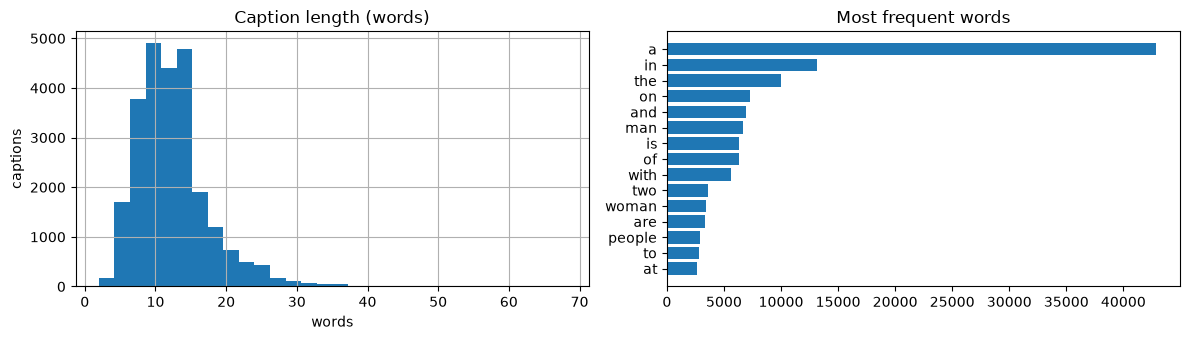

vocabulary size: 9,410 | mean length: 12.3 words


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
df["n_words"].hist(bins=30, ax=axes[0])
axes[0].set(title="Caption length (words)", xlabel="words", ylabel="captions")

vocab = Counter(w for c in df.caption for w in c.rstrip(".").replace(",", "").split())
top = vocab.most_common(15)
axes[1].barh([w for w, _ in top][::-1], [n for _, n in top][::-1])
axes[1].set(title="Most frequent words")
plt.tight_layout(); plt.show()

print(f"vocabulary size: {len(vocab):,} | mean length: {df.n_words.mean():.1f} words")

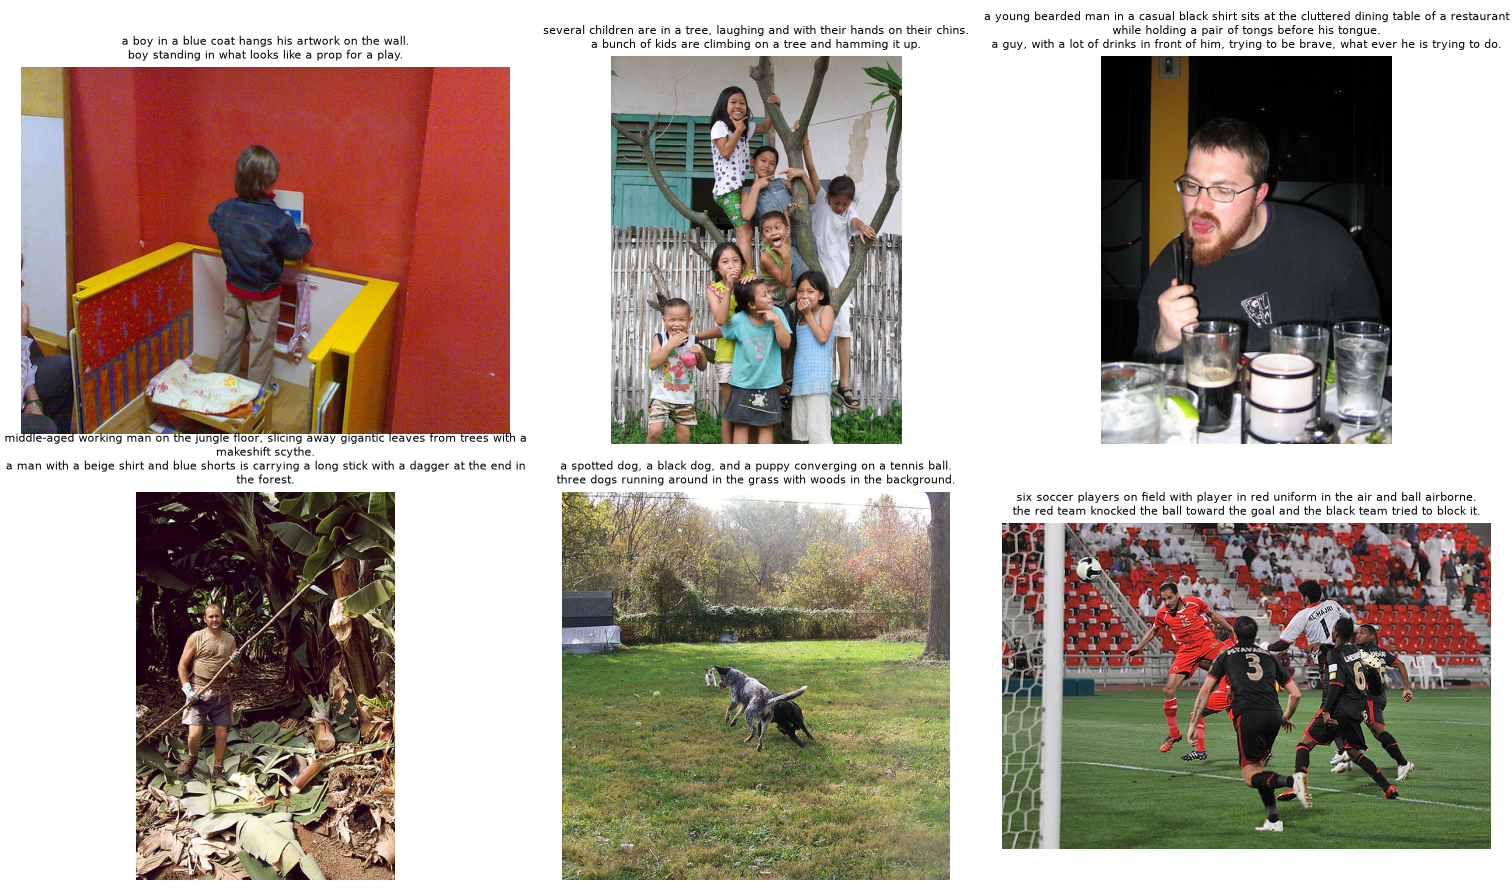

In [8]:
sample_ids = df.image_id.drop_duplicates().sample(6, random_state=SEED).tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, iid in zip(axes.flat, sample_ids):
    sub = df[df.image_id == iid]
    ax.imshow(Image.open(IMG_DIR / sub.filename.iloc[0]))
    ax.set_title("\n".join(sub.caption.head(2)), fontsize=8, wrap=True)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Split summary and saving the clean data

The split is by **image**, as Karpathy defined it, so no photo appears in more than one split. Splitting by caption would put the same photo in both train and test, which leaks test data into training.

In [9]:
assert df.groupby("image_id").split.nunique().max() == 1, "an image appears in more than one split"
df.to_csv(DATA_DIR / "captions_clean.csv", index=False)
print(df.groupby("split", sort=False).agg(images=("image_id", "nunique"), pairs=("caption", "size")))

       images  pairs
split               
train    2986  14907
val      1014   5070
test     1000   5000


## 6. Image → embedding pipeline (CLIP ViT-B/32)

* `CLIPProcessor` resizes to 224×224, center-crops, and normalises with CLIP's mean/std.
* `get_image_features` returns one **512-d vector** per image (vision encoder + projection).
* We **L2-normalise** the vectors, so cosine similarity becomes a plain dot product.
* Embeddings are computed **once per unique image** (not once per caption) and cached to `outputs/`.

In [10]:
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
n_params = sum(p.numel() for p in clip_model.parameters()) / 1e6
print(f"{CLIP_MODEL_NAME}: {n_params:.0f}M params, embedding dim = {clip_model.config.projection_dim}")


def as_tensor(out):
    # Newer transformers versions may return a ModelOutput instead of a tensor.
    return out if torch.is_tensor(out) else out.pooler_output


@torch.no_grad()
def embed_images(paths, batch_size=BATCH_SIZE):
    feats = []
    for i in tqdm(range(0, len(paths), batch_size), desc="CLIP images"):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i + batch_size]]
        inputs = clip_processor(images=imgs, return_tensors="pt").to(DEVICE)
        f = as_tensor(clip_model.get_image_features(**inputs))
        feats.append(torch.nn.functional.normalize(f, dim=-1).cpu())
    return torch.cat(feats)


@torch.no_grad()
def embed_texts(texts, batch_size=256):
    feats = []
    for i in range(0, len(texts), batch_size):
        inputs = clip_processor(text=texts[i:i + batch_size], return_tensors="pt",
                                padding=True, truncation=True).to(DEVICE)
        f = as_tensor(clip_model.get_text_features(**inputs))
        feats.append(torch.nn.functional.normalize(f, dim=-1).cpu())
    return torch.cat(feats)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

openai/clip-vit-base-patch32: 151M params, embedding dim = 512


In [11]:
EMB_PATH = OUT_DIR / "clip_image_embeddings.pt"
images_df = df.drop_duplicates("image_id")[["image_id", "filename", "split"]].reset_index(drop=True)

if EMB_PATH.exists() and torch.load(EMB_PATH)["image_ids"] == images_df.image_id.tolist():
    image_emb = torch.load(EMB_PATH)["embeddings"]
    print("loaded cached embeddings")
else:
    image_emb = embed_images([IMG_DIR / f for f in images_df.filename])
    torch.save({"image_ids": images_df.image_id.tolist(), "embeddings": image_emb,
                "model": CLIP_MODEL_NAME}, EMB_PATH)

print("image embeddings:", tuple(image_emb.shape), "| norms ≈", image_emb.norm(dim=-1)[:3].tolist())

CLIP images:   0%|          | 0/79 [00:00<?, ?it/s]

image embeddings: (5000, 512) | norms ≈ [0.9999999403953552, 1.0, 0.9999998211860657]


### 6.1 Sanity check: zero-shot image ↔ caption retrieval

Before building anything on these embeddings, check that they make sense. We use the standard **Flickr30k 1K test** retrieval protocol (1,000 images, 5,000 captions):
* **Image→Text:** for each image, is at least one of its own 5 captions among the top-k most similar captions?
* **Text→Image:** for each caption, is its own image among the top-k most similar images?

Recall@k far above chance means the pipeline works. Because this is the standard Karpathy test set, the numbers can be compared directly with the zero-shot results in the CLIP paper (Radford et al., 2021), which makes them a solid **baseline** for the report.

In [12]:
test_imgs = images_df[images_df.split == "test"].reset_index(drop=True)
test_caps = df[df.split == "test"].reset_index(drop=True)
img_index = {iid: i for i, iid in enumerate(images_df.image_id)}

I = image_emb[[img_index[i] for i in test_imgs.image_id]]
T = embed_texts(test_caps.caption.tolist())
sim = I @ T.T                                    # [n_images, n_captions]
cap_owner = torch.tensor(test_caps.image_id.map({iid: i for i, iid in enumerate(test_imgs.image_id)}).values)


def i2t_recall(k):
    topk = sim.topk(k, dim=1).indices                                   # captions per image
    return (cap_owner[topk] == torch.arange(sim.size(0))[:, None]).any(dim=1).float().mean().item()


def t2i_recall(k):
    topk = sim.T.topk(k, dim=1).indices                                 # images per caption
    return (topk == cap_owner[:, None]).any(dim=1).float().mean().item()


retrieval = pd.DataFrame({f"R@{k}": [i2t_recall(k), t2i_recall(k), k / sim.size(0)]
                          for k in (1, 5, 10)}, index=["Image→Text", "Text→Image", "chance (T→I)"])
print(f"{sim.size(0)} test images x {sim.size(1)} captions")
(retrieval * 100).round(1)

1000 test images x 5000 captions


,R@1,R@5,R@10
Image→Text,79.5,95.0,98.2
Text→Image,58.7,83.4,90.0
chance (T→I),0.1,0.5,1.0


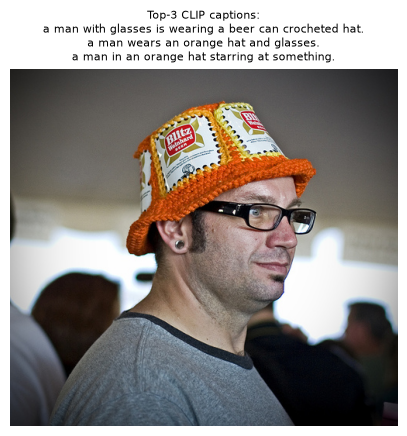

In [13]:
q = 0
best = sim[q].topk(3).indices
plt.figure(figsize=(5, 5)); plt.imshow(Image.open(IMG_DIR / test_imgs.filename[q])); plt.axis("off")
plt.title("Top-3 CLIP captions:\n" + "\n".join(test_caps.caption[i.item()] for i in best), fontsize=8)
plt.show()

## 7. Tokenize captions with the GPT-2 tokenizer

* GPT-2 uses **byte-level BPE** (50,257 tokens), so it never produces an unknown token.
* GPT-2 has **no pad token**. The usual fix is `pad_token = eos_token`; the `attention_mask` then tells real tokens apart from padding. During training, set padded label positions to `-100` so the loss ignores them.
* We append `<|endoftext|>` (EOS) to each caption so the decoder learns when to stop.
* `MAX_LEN` is picked from the data (99th percentile) rather than guessed.

In [14]:
tokenizer = GPT2TokenizerFast.from_pretrained(GPT2_MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

captions_eos = [c + tokenizer.eos_token for c in df.caption]
lengths = [len(ids) for ids in tokenizer(captions_eos)["input_ids"]]
MAX_LEN = int(np.percentile(lengths, 99))
print(f"token length: mean={np.mean(lengths):.1f}  max={max(lengths)}  -> MAX_LEN={MAX_LEN} "
      f"({np.mean(np.array(lengths) > MAX_LEN) * 100:.1f}% truncated)")

enc = tokenizer(captions_eos, padding="max_length", truncation=True,
                max_length=MAX_LEN, return_tensors="pt")
print("input_ids:", tuple(enc["input_ids"].shape))

ex = enc["input_ids"][0]
print("\ncaption :", df.caption[0])
print("ids     :", ex[:enc["attention_mask"][0].sum()].tolist())
print("tokens  :", tokenizer.convert_ids_to_tokens(ex[:enc["attention_mask"][0].sum()]))
print("decoded :", tokenizer.decode(ex, skip_special_tokens=True))

token length: mean=15.2  max=88  -> MAX_LEN=34 (1.0% truncated)


input_ids: (24977, 34)

caption : a boy wearing heavy-duty boots and a sweater, steers his wagon as he walks to the park.
ids     : [64, 2933, 5762, 4334, 12, 26278, 14412, 290, 257, 35685, 11, 2876, 364, 465, 31860, 355, 339, 11114, 284, 262, 3952, 13, 50256]
tokens  : ['a', 'Ġboy', 'Ġwearing', 'Ġheavy', '-', 'duty', 'Ġboots', 'Ġand', 'Ġa', 'Ġsweater', ',', 'Ġste', 'ers', 'Ġhis', 'Ġwagon', 'Ġas', 'Ġhe', 'Ġwalks', 'Ġto', 'Ġthe', 'Ġpark', '.', '<|endoftext|>']
decoded : a boy wearing heavy-duty boots and a sweater, steers his wagon as he walks to the park.


In [15]:
TOK_PATH = OUT_DIR / "gpt2_tokens.pt"
torch.save({
    "input_ids": enc["input_ids"],
    "attention_mask": enc["attention_mask"],
    "image_index": torch.tensor(df.image_id.map(img_index).values),  # row in image_emb
    "split": df.split.tolist(),
    "captions": df.caption.tolist(),
    "max_len": MAX_LEN,
    "tokenizer": GPT2_MODEL_NAME,
}, TOK_PATH)
print("saved", TOK_PATH)

saved /Users/garimadaryani/Documents/NEU/image-classification-captioning/Generative Project - Image Captioning/outputs/gpt2_tokens.pt


## 8. Put it together: a PyTorch `Dataset` for the next phase

Each item is one **(CLIP image embedding, GPT-2 caption tokens)** pair, which is exactly what a CLIP-prefix captioning model (e.g. ClipCap) trains on.

In [16]:
from torch.utils.data import Dataset, DataLoader


class CaptionEmbeddingDataset(Dataset):
    def __init__(self, emb_path, tok_path, split):
        emb, tok = torch.load(emb_path), torch.load(tok_path)
        keep = [i for i, s in enumerate(tok["split"]) if s == split]
        self.image_emb = emb["embeddings"]
        self.input_ids = tok["input_ids"][keep]
        self.attention_mask = tok["attention_mask"][keep]
        self.image_index = tok["image_index"][keep]

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, i):
        labels = self.input_ids[i].clone()
        labels[self.attention_mask[i] == 0] = -100          # ignore padding in the loss
        return {"clip_embedding": self.image_emb[self.image_index[i]],
                "input_ids": self.input_ids[i],
                "attention_mask": self.attention_mask[i],
                "labels": labels}


loaders = {s: DataLoader(CaptionEmbeddingDataset(EMB_PATH, TOK_PATH, s),
                         batch_size=32, shuffle=(s == "train"))
           for s in ("train", "val", "test")}
batch = next(iter(loaders["train"]))
for k, v in batch.items():
    print(f"{k:15s} {tuple(v.shape)}  {v.dtype}")
print({s: len(l.dataset) for s, l in loaders.items()})

clip_embedding  (32, 512)  torch.float32
input_ids       (32, 34)  torch.int64
attention_mask  (32, 34)  torch.int64
labels          (32, 34)  torch.int64
{'train': 14907, 'val': 5070, 'test': 5000}


## 9. Summary and outputs

| File | Contents |
|---|---|
| `data/flickr30k_subset/images/*.jpg` | 5,000 images: all Karpathy test (1,000) and val (1,014) images + 2,986 sampled train images |
| `data/flickr30k_subset/captions_clean.csv` | cleaned captions with `image_id`, `split`, raw vs cleaned text |
| `outputs/clip_image_embeddings.pt` | L2-normalised 512-d CLIP ViT-B/32 embedding per image |
| `outputs/gpt2_tokens.pt` | GPT-2 `input_ids` / `attention_mask` per caption + link to its image |

**Next steps**
1. A mapping network (MLP or small transformer) that turns a CLIP embedding into *k* GPT-2 "prefix" token embeddings.
2. Train it on `loaders["train"]` with GPT-2 frozen at first, then optionally fine-tune GPT-2.
3. Generate captions (greedy or beam search) and evaluate with BLEU, METEOR, CIDEr and CLIPScore on the Karpathy 1K test set, alongside the CLIP retrieval baseline above.